# Import Module

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

# Mempersiapakan Data

In [2]:
df = pd.read_csv("E:/KP RAFI RIDHO RAMADHAN\Data/raw_juni_seminggu.csv")

df['timestamp'] = pd.to_datetime(df['timestamp'])

df.set_index('timestamp', inplace=True)

df.head()

,bmp388Pressure,bmp388Temp,bmp388ApprxAltitude,sht85Humi,sht85Temp,co2,ch4,H2OSHT85,utara,barat,timur,selatan,bawah,atas
timestamp,,,,,,,,,,,,,,
2024-06-10 13:06:01.353,79.026558,24.340239,37.528976,74.532692,27.232393,364,0,1943.793818,1.05,0.00,5.68,0.46,4.60,0.00
2024-06-10 13:06:01.436,100.875145,27.721346,37.549667,74.512856,27.275118,363,0,1947.872620,1.05,0.87,5.92,0.62,4.86,0.00
2024-06-10 13:06:01.600,100.876099,27.732904,37.537556,74.476234,27.275118,363,0,1946.915292,1.14,0.87,5.68,0.53,4.60,0.28
2024-06-10 13:06:01.763,100.874657,27.744940,37.568340,74.431984,27.259096,363,0,1944.035748,1.14,0.87,5.68,0.62,4.86,0.00
2024-06-10 13:06:01.926,100.874779,27.753908,37.621830,74.491493,27.301826,363,0,1950.191300,1.14,0.87,5.92,0.53,4.86,0.00


In [3]:
# Ubah nama kolom
df.rename(columns={'bmp388Pressure': 'Air Pressure (kPa)', 'bmp388Temp': 'Air Temperature (Celcius)', 'sht85Humi': 'Relatif Humidity (%)',
                   'sht85Temp': 'Temperature (Celsius)', 'co2': 'C02 mole fraction (µmol/mol_a)', 'bawah': 'bawah (m/s)', 'atas':'atas (m/s)',
                   'H2OSHT85':'Water Vapor Mass Density (kg/m^3)', 'bmp388ApprxAltitude': 'Altitude (MSAL)', 'ch4': 'CH4 mole fraction (µmol/mol_a)', 'utara':'utara (m/s)',
                   'barat': 'barat (m/s)', 'timur': 'timur (m/s)', 'selatan':'selatan (m/s)'}, inplace=True)

# Pembersihan Data

In [4]:
# Menampilkan informasi data
df.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 1945487 entries, 2024-06-10 13:06:01.353000 to 2024-06-17 23:36:00.969000
Data columns (total 14 columns):
 #   Column                             Dtype  
---  ------                             -----  
 0   Air Pressure (kPa)                 float64
 1   Air Temperature (Celcius)          float64
 2   Altitude (MSAL)                    float64
 3   Relatif Humidity (%)               float64
 4   Temperature (Celsius)              float64
 5   C02 mole fraction (µmol/mol_a)     int64  
 6   CH4 mole fraction (µmol/mol_a)     int64  
 7   Water Vapor Mass Density (kg/m^3)  float64
 8   utara (m/s)                        float64
 9   barat (m/s)                        float64
 10  timur (m/s)                        float64
 11  selatan (m/s)                      float64
 12  bawah (m/s)                        float64
 13  atas (m/s)                         float64
dtypes: float64(12), int64(2)
memory usage: 222.6 MB


In [5]:
# Menampilkan deskripsi data
df.describe()

,Air Pressure (kPa),Air Temperature (Celcius),Altitude (MSAL),Relatif Humidity (%),Temperature (Celsius),C02 mole fraction (µmol/mol_a),CH4 mole fraction (µmol/mol_a),Water Vapor Mass Density (kg/m^3),utara (m/s),barat (m/s),timur (m/s),selatan (m/s),bawah (m/s),atas (m/s)
count,1.945487e+06,1.945487e+06,1.945487e+06,1.945487e+06,1.945487e+06,1.945487e+06,1945487.0,1.945487e+06,1.945487e+06,1.945487e+06,1.945487e+06,1.945487e+06,1.945487e+06,1.945487e+06
mean,1.009692e+02,2.678724e+01,2.950469e+01,8.675262e+01,2.688464e+01,4.378448e+02,0.0,2.193253e+03,2.827060e+00,3.779728e-01,2.653674e-01,4.490666e-01,4.443083e+00,2.952205e-02
std,2.744461e-01,3.403961e+00,1.470683e+01,1.213063e+01,3.107304e+00,8.184457e+01,0.0,1.038379e+02,8.332367e-01,1.278594e+00,1.565420e+00,7.945330e-01,3.415049e+00,1.023922e+00
min,7.902656e+01,2.241606e+01,-7.200201e-01,5.020676e+01,2.272221e+01,0.000000e+00,0.0,1.827950e+03,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,1.008513e+02,2.393463e+01,1.812902e+01,7.723354e+01,2.427634e+01,3.690000e+02,0.0,2.130746e+03,2.710000e+00,0.000000e+00,0.000000e+00,3.100000e-01,7.400000e-01,0.000000e+00
50%,1.009727e+02,2.543564e+01,2.936660e+01,9.187762e+01,2.571832e+01,4.170000e+02,0.0,2.181082e+03,2.790000e+00,0.000000e+00,0.000000e+00,3.100000e-01,4.810000e+00,0.000000e+00
75%,1.011075e+02,2.991052e+01,3.950988e+01,9.687190e+01,2.978790e+01,4.930000e+02,0.0,2.259931e+03,2.790000e+00,8.700000e-01,0.000000e+00,4.000000e-01,6.540000e+00,0.000000e+00
max,1.013338e+02,3.529694e+01,6.512341e+01,9.914397e+01,3.402838e+01,7.140000e+02,0.0,2.569588e+03,5.431000e+01,8.277000e+01,7.956000e+01,5.328000e+01,7.933000e+01,7.709000e+01


In [6]:
# Menampilkan data null
df.isnull().sum()

Air Pressure (kPa)                   0
Air Temperature (Celcius)            0
Altitude (MSAL)                      0
Relatif Humidity (%)                 0
Temperature (Celsius)                0
C02 mole fraction (µmol/mol_a)       0
CH4 mole fraction (µmol/mol_a)       0
Water Vapor Mass Density (kg/m^3)    0
utara (m/s)                          0
barat (m/s)                          0
timur (m/s)                          0
selatan (m/s)                        0
bawah (m/s)                          0
atas (m/s)                           0
dtype: int64

In [7]:
# Menampilkan data NaN
df.isna().sum()

Air Pressure (kPa)                   0
Air Temperature (Celcius)            0
Altitude (MSAL)                      0
Relatif Humidity (%)                 0
Temperature (Celsius)                0
C02 mole fraction (µmol/mol_a)       0
CH4 mole fraction (µmol/mol_a)       0
Water Vapor Mass Density (kg/m^3)    0
utara (m/s)                          0
barat (m/s)                          0
timur (m/s)                          0
selatan (m/s)                        0
bawah (m/s)                          0
atas (m/s)                           0
dtype: int64

# Mengatasi Outlier Menggunakan IQR

**Mengecek Distribusi Data Sebleum Pembersihan**

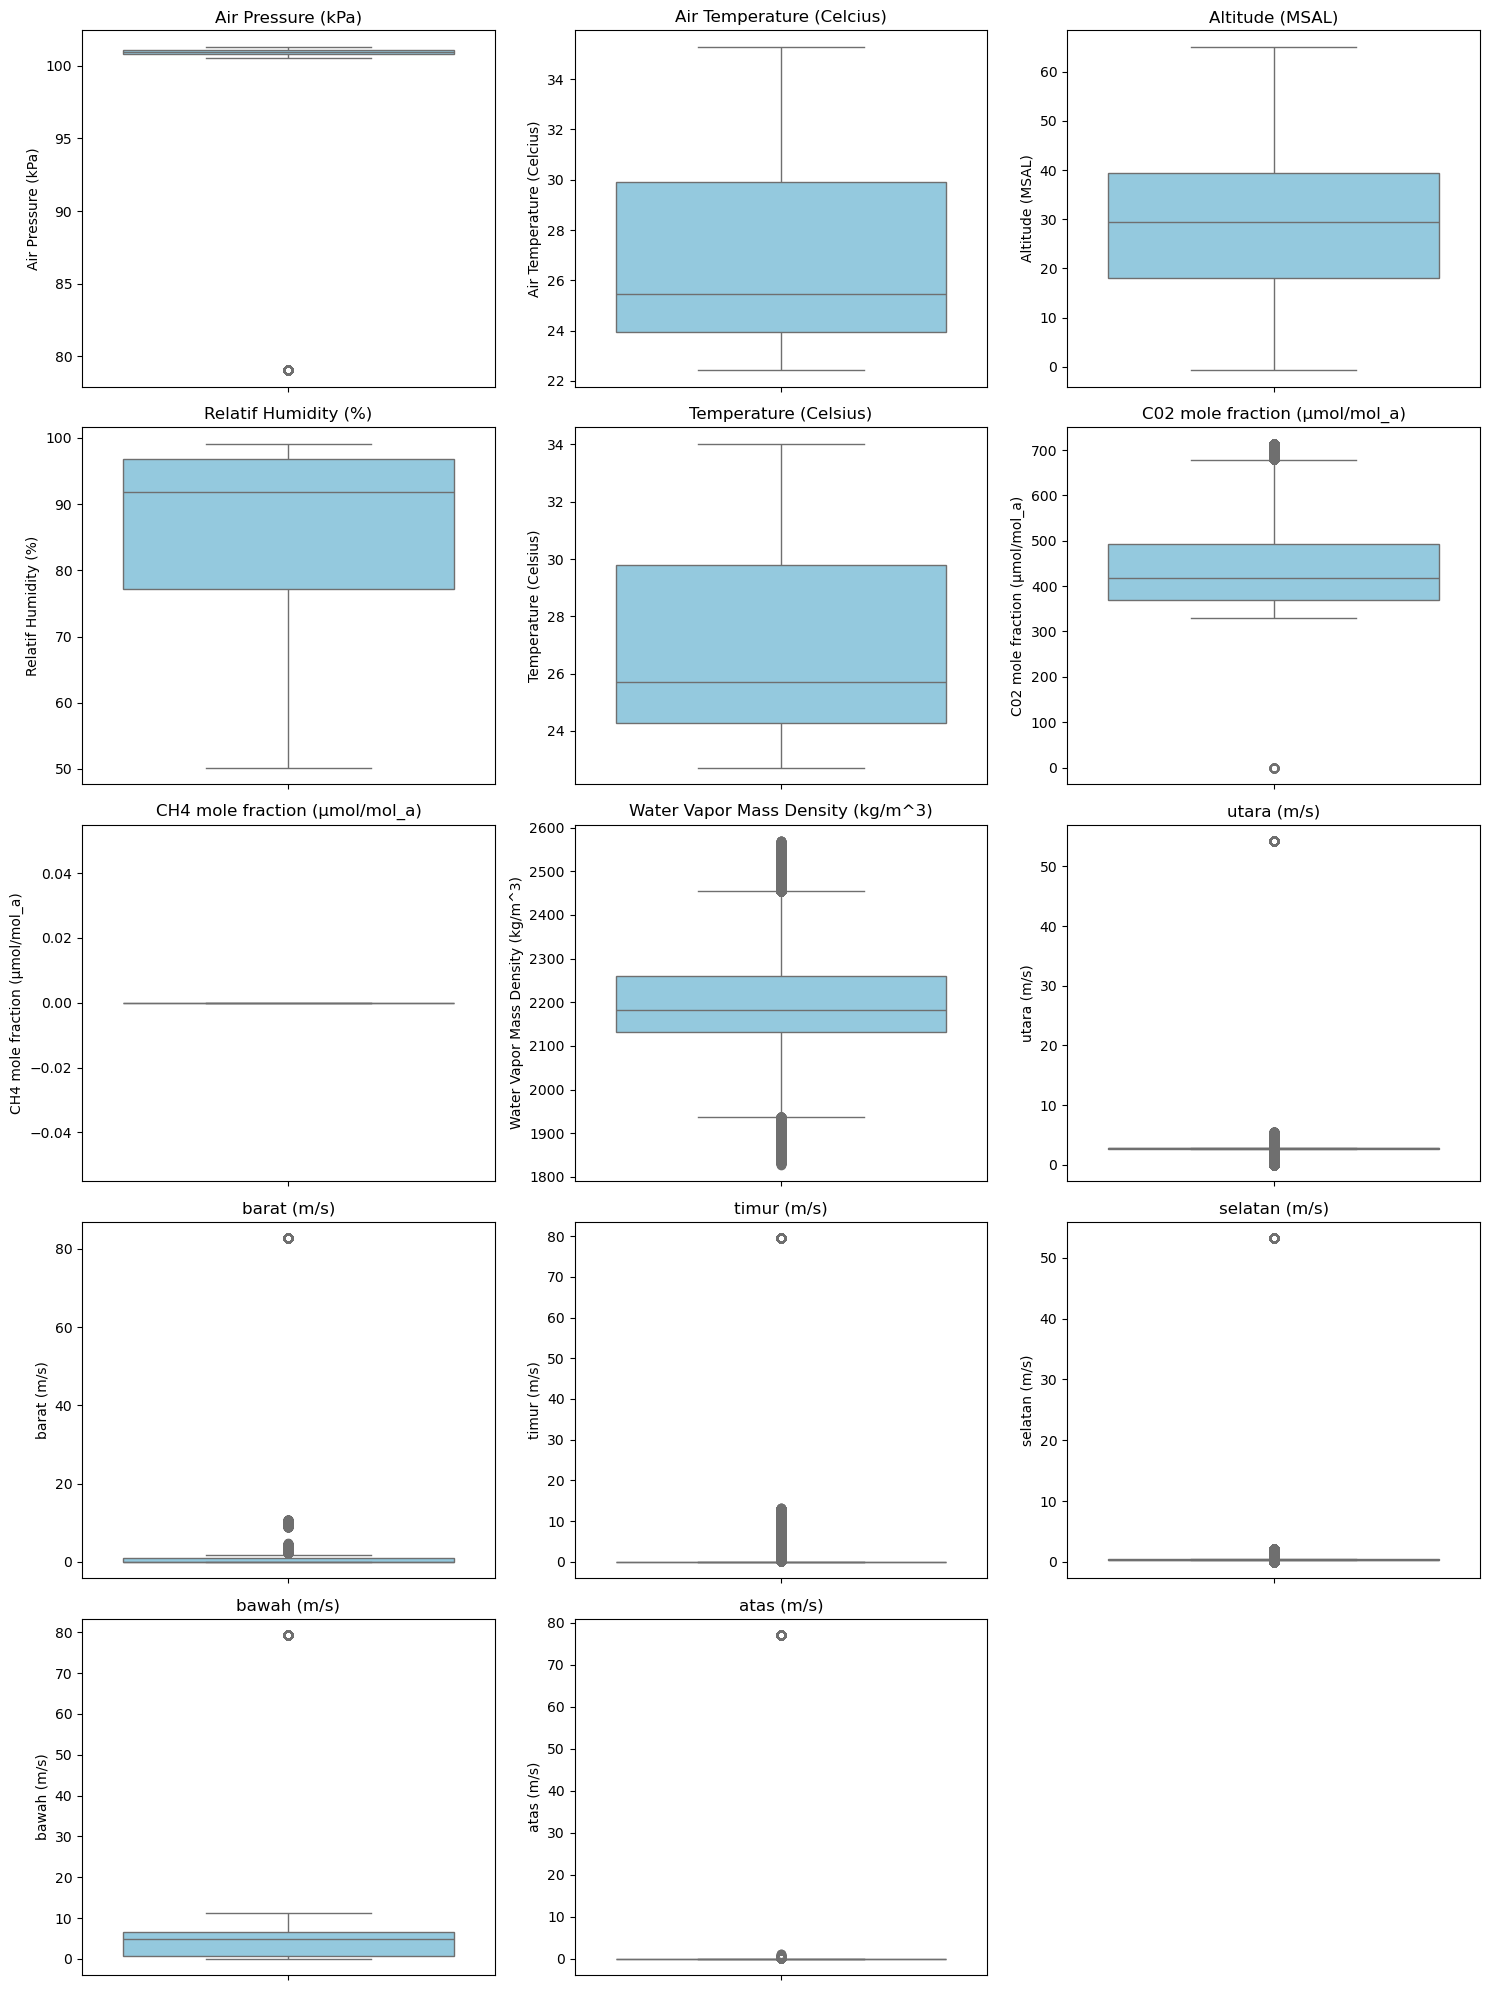

In [8]:
# Membuat boxplot
cols = 3
fig, ax = plt.subplots(-(-len(df.columns)//cols), cols, figsize=(15, 20))
for a, c in zip(ax.ravel(), df.columns):
    sns.boxplot(y=df[c], ax=a, color='skyblue'); a.set_title(c)
for a in ax.ravel()[len(df.columns):]: a.remove()
plt.tight_layout(); plt.show()

**Outlier Seluruh Parameter**

In [9]:
columns = [
    'Air Pressure (kPa)',
    'Air Temperature (Celcius)',
    'Altitude (MSAL)',
    'Relatif Humidity (%)',
    'Temperature (Celsius)',
    'C02 mole fraction (µmol/mol_a)',
    'CH4 mole fraction (µmol/mol_a)',
    'Water Vapor Mass Density (kg/m^3)',
    'utara (m/s)',
    'barat (m/s)',
    'timur (m/s)',
    'selatan (m/s)',
    'bawah (m/s)'
]

for col in columns:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    # Ganti outlier dengan NaN
    df[col] = df[col].where((df[col] >= lower_bound) & (df[col] <= upper_bound), np.nan)

    # Khusus Air Temperature (Celcius)
    if col == 'Air Temperature (Celcius)':
        specific_outliers = [24.34023857, 24.05245972]
        df[col] = df[col].replace(specific_outliers, np.nan)

    # Khusus bawah dan atas: ganti nilai > 7 dengan NaN
    if col in ['bawah (m/s)']:
        df.loc[df[col] > 7, col] = pd.NA

    # Interpolasi berbasis waktu
    df[col] = df[col].interpolate(method='time')


In [10]:
df.loc[df['atas (m/s)'] > 7, 'atas (m/s)'] = pd.NA

# Interpolasi berbasis waktu
df['atas (m/s)'] = df['atas (m/s)'].interpolate(method='time')

**Visualisasi**

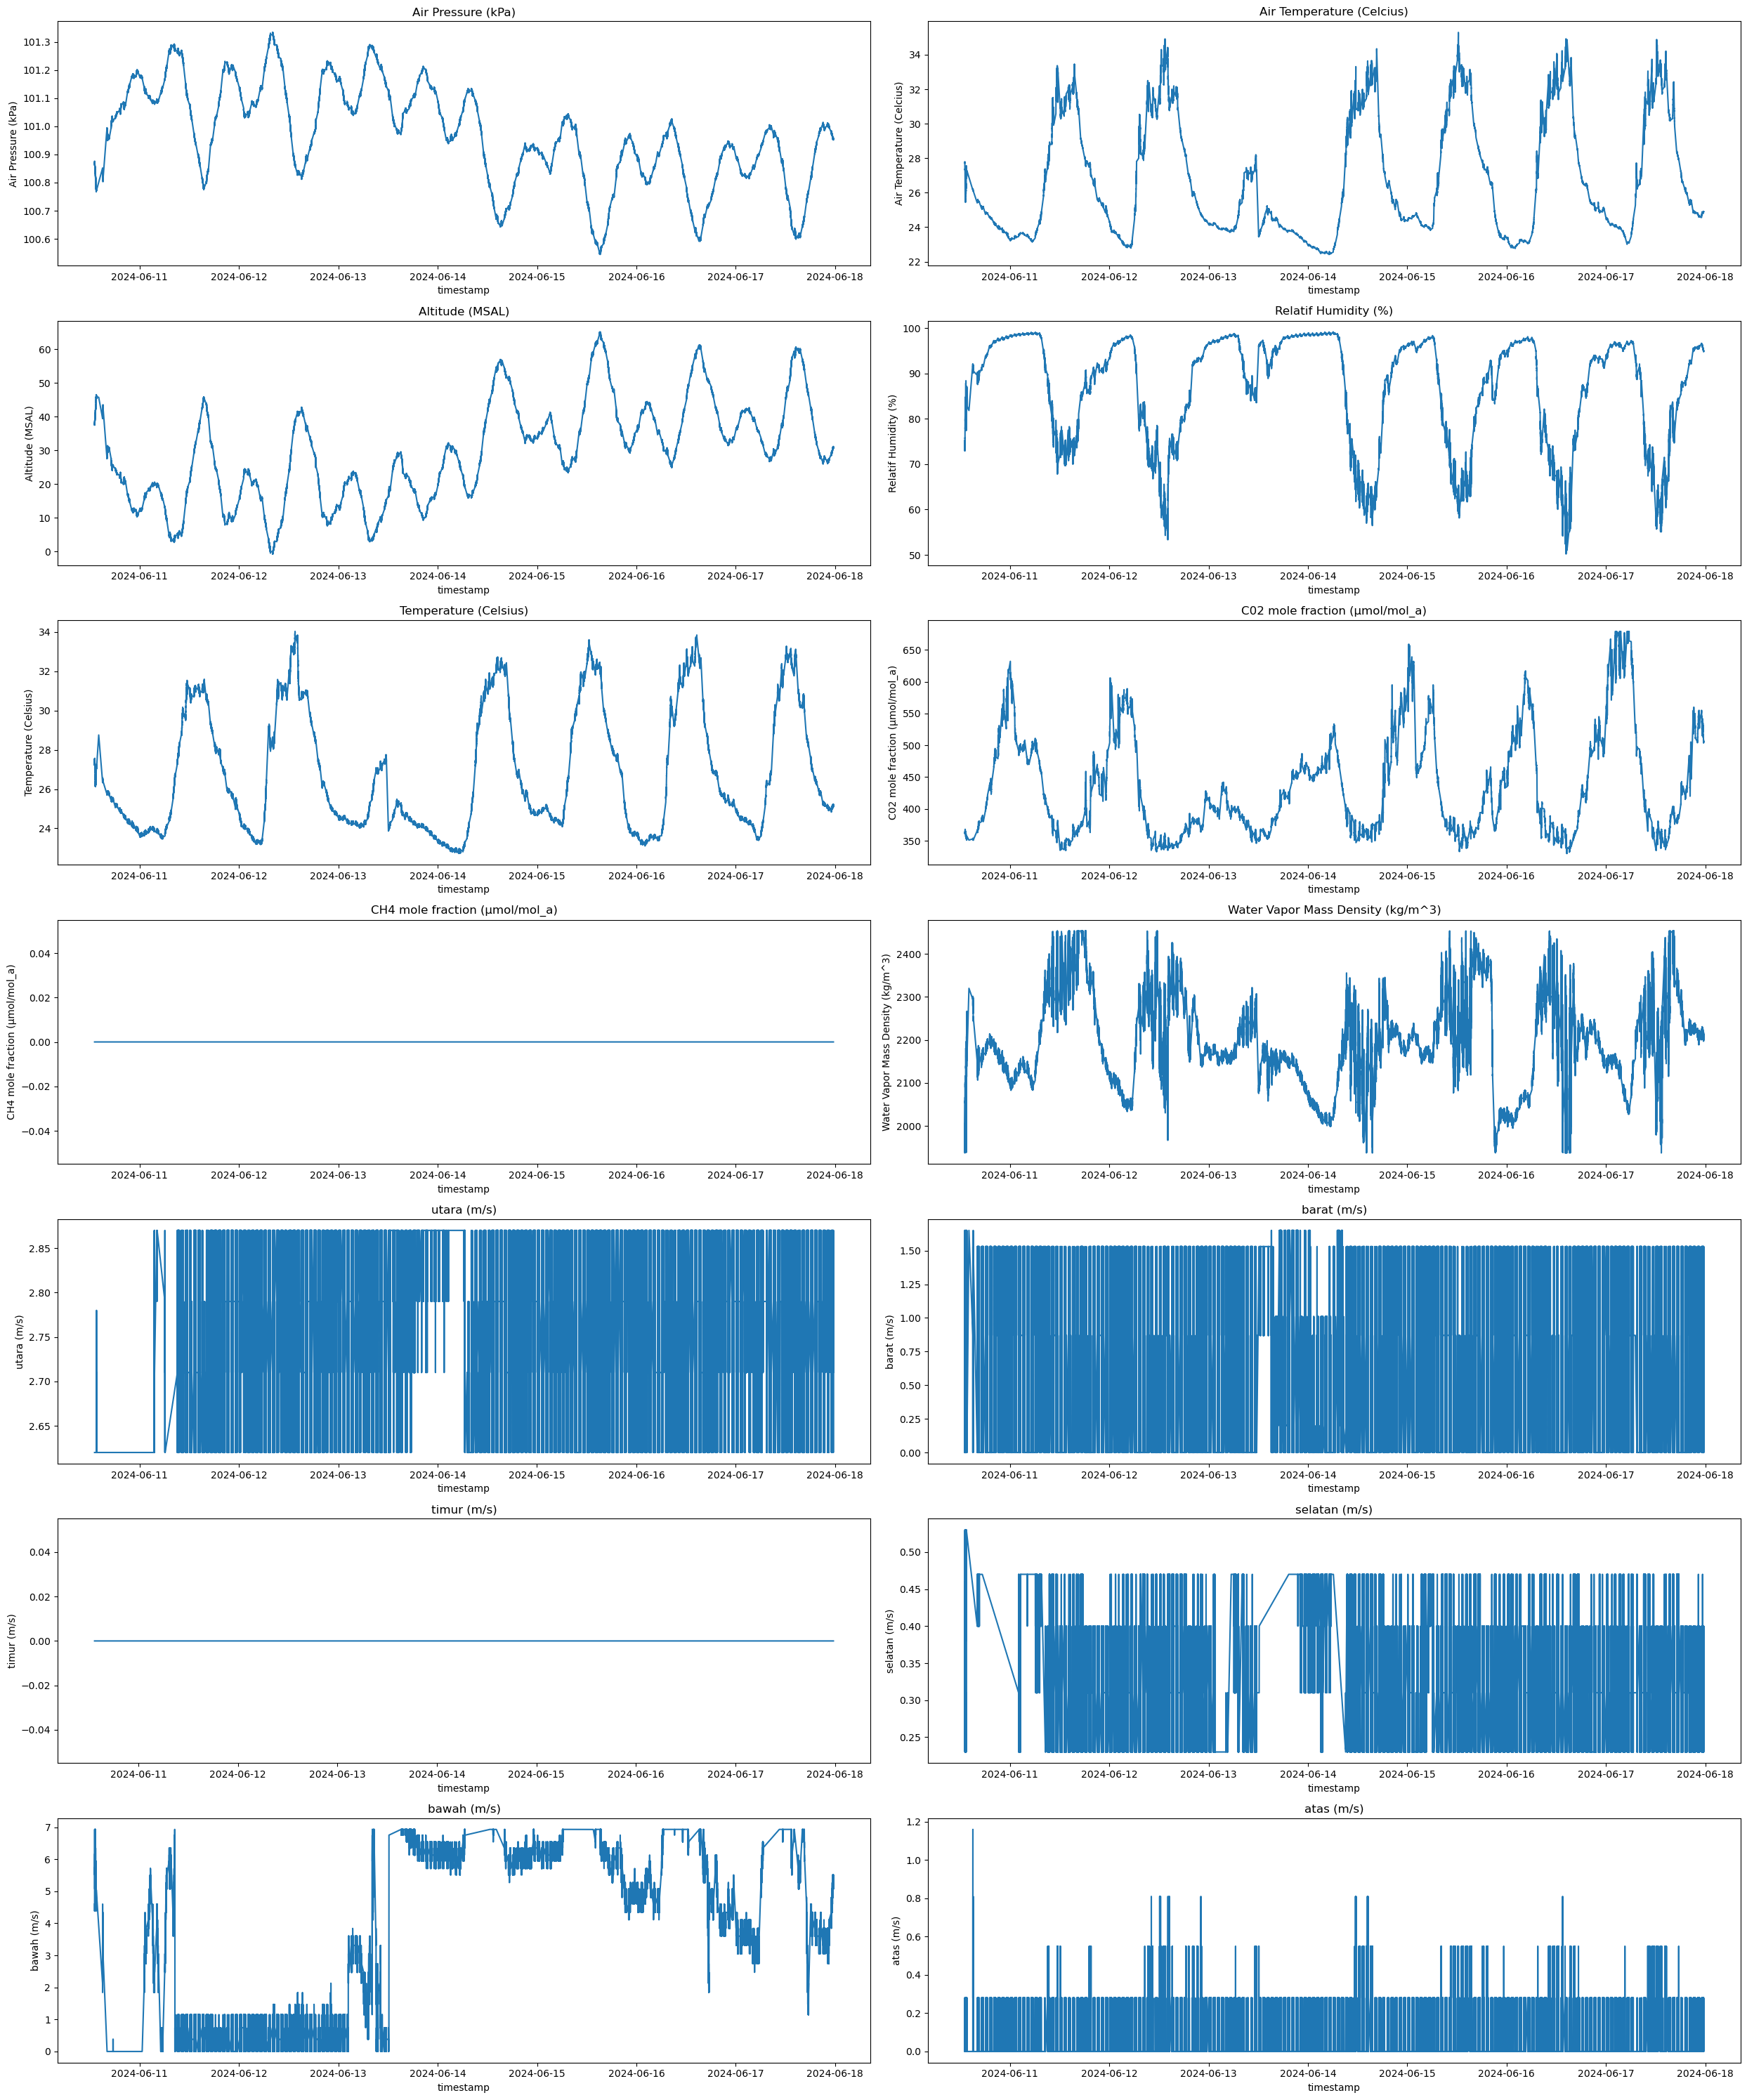

In [11]:
# Visualisasi Data
columns = [
    'Air Pressure (kPa)',
    'Air Temperature (Celcius)',
    'Altitude (MSAL)',
    'Relatif Humidity (%)',
    'Temperature (Celsius)',
    'C02 mole fraction (µmol/mol_a)',
    'CH4 mole fraction (µmol/mol_a)',
    'Water Vapor Mass Density (kg/m^3)',
    'utara (m/s)',
    'barat (m/s)',
    'timur (m/s)',
    'selatan (m/s)',
    'bawah (m/s)',
    'atas (m/s)'
]


fig, ax = plt.subplots(-(-len(columns)//2), 2, figsize=(25,30))
[ (sns.lineplot(x=df.index, y=df[c], ax=a), a.set_title(c)) for a,c in zip(ax.ravel(), columns) ]
plt.tight_layout(); plt.show()

In [12]:
# Menampilkan data NaN
df.isna().sum()

Air Pressure (kPa)                      1
Air Temperature (Celcius)               1
Altitude (MSAL)                         0
Relatif Humidity (%)                    0
Temperature (Celsius)                   0
C02 mole fraction (µmol/mol_a)          0
CH4 mole fraction (µmol/mol_a)          0
Water Vapor Mass Density (kg/m^3)       0
utara (m/s)                           383
barat (m/s)                             0
timur (m/s)                          7009
selatan (m/s)                           0
bawah (m/s)                             0
atas (m/s)                              0
dtype: int64

In [13]:
df.head()

,Air Pressure (kPa),Air Temperature (Celcius),Altitude (MSAL),Relatif Humidity (%),Temperature (Celsius),C02 mole fraction (µmol/mol_a),CH4 mole fraction (µmol/mol_a),Water Vapor Mass Density (kg/m^3),utara (m/s),barat (m/s),timur (m/s),selatan (m/s),bawah (m/s),atas (m/s)
timestamp,,,,,,,,,,,,,,
2024-06-10 13:06:01.353,NaN,NaN,37.528976,74.532692,27.232393,364.0,0,1943.793818,NaN,0.00,NaN,0.460000,4.60,0.00
2024-06-10 13:06:01.436,100.875145,27.721346,37.549667,74.512856,27.275118,363.0,0,1947.872620,NaN,0.87,NaN,0.483522,4.86,0.00
2024-06-10 13:06:01.600,100.876099,27.732904,37.537556,74.476234,27.275118,363.0,0,1946.915292,NaN,0.87,NaN,0.530000,4.60,0.28
2024-06-10 13:06:01.763,100.874657,27.744940,37.568340,74.431984,27.259096,363.0,0,1944.035748,NaN,0.87,NaN,0.530000,4.86,0.00
2024-06-10 13:06:01.926,100.874779,27.753908,37.621830,74.491493,27.301826,363.0,0,1950.191300,NaN,0.87,NaN,0.530000,4.86,0.00


In [15]:
# Mengisi nilai NaN dengan Modus
for col in ['Air Pressure (kPa)', 'Air Temperature (Celcius)', 'utara (m/s)', 'timur (m/s)']:
    mode_val = df[col].mode()
    if not mode_val.empty:
        df[col].fillna(mode_val[0], inplace=True)

In [16]:
df.isna().sum()

Air Pressure (kPa)                   0
Air Temperature (Celcius)            0
Altitude (MSAL)                      0
Relatif Humidity (%)                 0
Temperature (Celsius)                0
C02 mole fraction (µmol/mol_a)       0
CH4 mole fraction (µmol/mol_a)       0
Water Vapor Mass Density (kg/m^3)    0
utara (m/s)                          0
barat (m/s)                          0
timur (m/s)                          0
selatan (m/s)                        0
bawah (m/s)                          0
atas (m/s)                           0
dtype: int64

**Mengecek Distribusi Data Setelah Pembersihan**

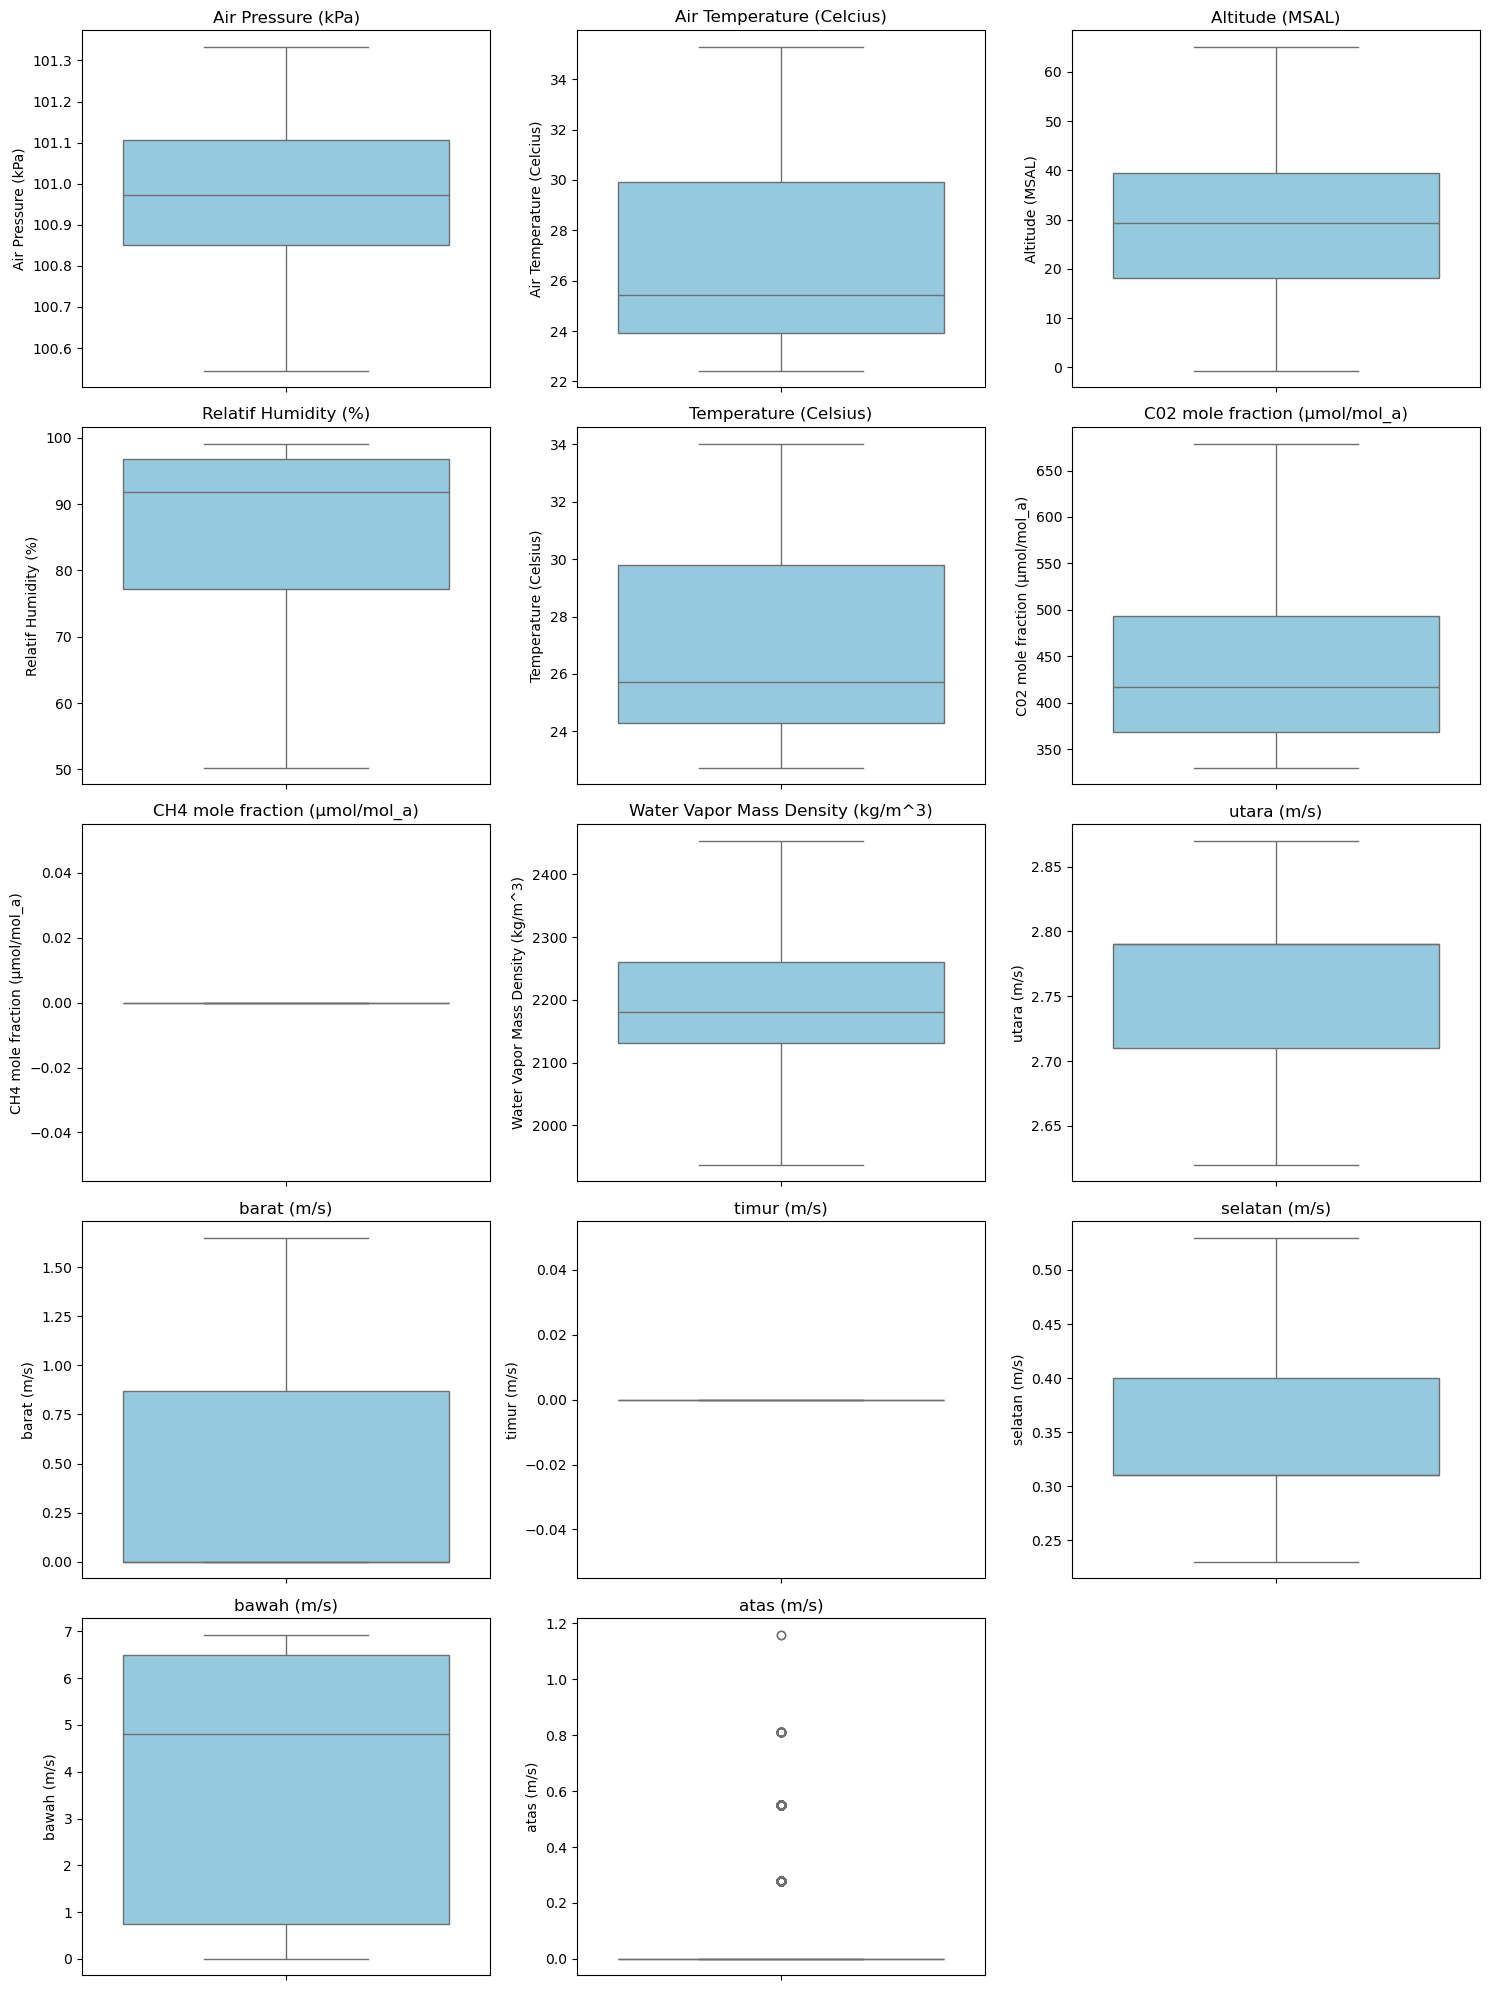

In [17]:
cols = 3
fig, ax = plt.subplots(-(-len(df.columns)//cols), cols, figsize=(15, 20))
for a, c in zip(ax.ravel(), df.columns):
    sns.boxplot(y=df[c], ax=a, color='skyblue'); a.set_title(c)
for a in ax.ravel()[len(df.columns):]: a.remove()
plt.tight_layout(); plt.show()

# Menyimpan Data

In [18]:
# Simpan data ke csv
df.to_csv('E:/KP RAFI RIDHO RAMADHAN/Hasil/data_juni_ST2_7D_clean.csv')